In [1]:
import os
import zipfile
import urllib.request
from pathlib import Path

# Rutas de datos
DATA_RAW_DIR = Path("../data/raw")
DATA_RAW_DIR.mkdir(parents=True, exist_ok=True)

ZIP_URL = "https://storage.googleapis.com/datascience-materials/dogs-vs-cats.zip"
ZIP_PATH = DATA_RAW_DIR / "dogs-vs-cats.zip"

# 1. Descargar el archivo zip (si no existe ya)
if not ZIP_PATH.exists():
    print(f"Descargando dataset desde {ZIP_URL}...")
    urllib.request.urlretrieve(ZIP_URL, ZIP_PATH)
    print("¡Descarga completada!")
else:
    print(f"El archivo {ZIP_PATH.name} ya existe. Omitiendo descarga.")

# 2. Descomprimir el archivo zip
EXTRACT_DIR = DATA_RAW_DIR
print(f"Descomprimiendo en {EXTRACT_DIR}...")
with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("¡Extracción finalizada!")


El archivo dogs-vs-cats.zip ya existe. Omitiendo descarga.
Descomprimiendo en ..\data\raw...


KeyboardInterrupt: 

In [ ]:
train_dir = DATA_RAW_DIR / "train"
if train_dir.exists():
    all_files = os.listdir(train_dir)
    dog_files = [f for f in all_files if f.startswith("dog")]
    cat_files = [f for f in all_files if f.startswith("cat")]
    
    print(f"Total de imágenes en train: {len(all_files)}")
    print(f"Fotos de perros (dog): {len(dog_files)}")
    print(f"Fotos de gatos (cat): {len(cat_files)}")
    print(f"Ejemplos de archivos: {all_files[:5]}")
else:
    print(f"Carpeta no encontrada en {train_dir}. Contenido en raw:", os.listdir(DATA_RAW_DIR))


Total de imágenes en train: 25000
Fotos de perros (dog): 12500
Fotos de gatos (cat): 12500
Ejemplos de archivos: ['cat.0.jpg', 'cat.1.jpg', 'cat.10.jpg', 'cat.100.jpg', 'cat.1000.jpg']


Visualizando perros...


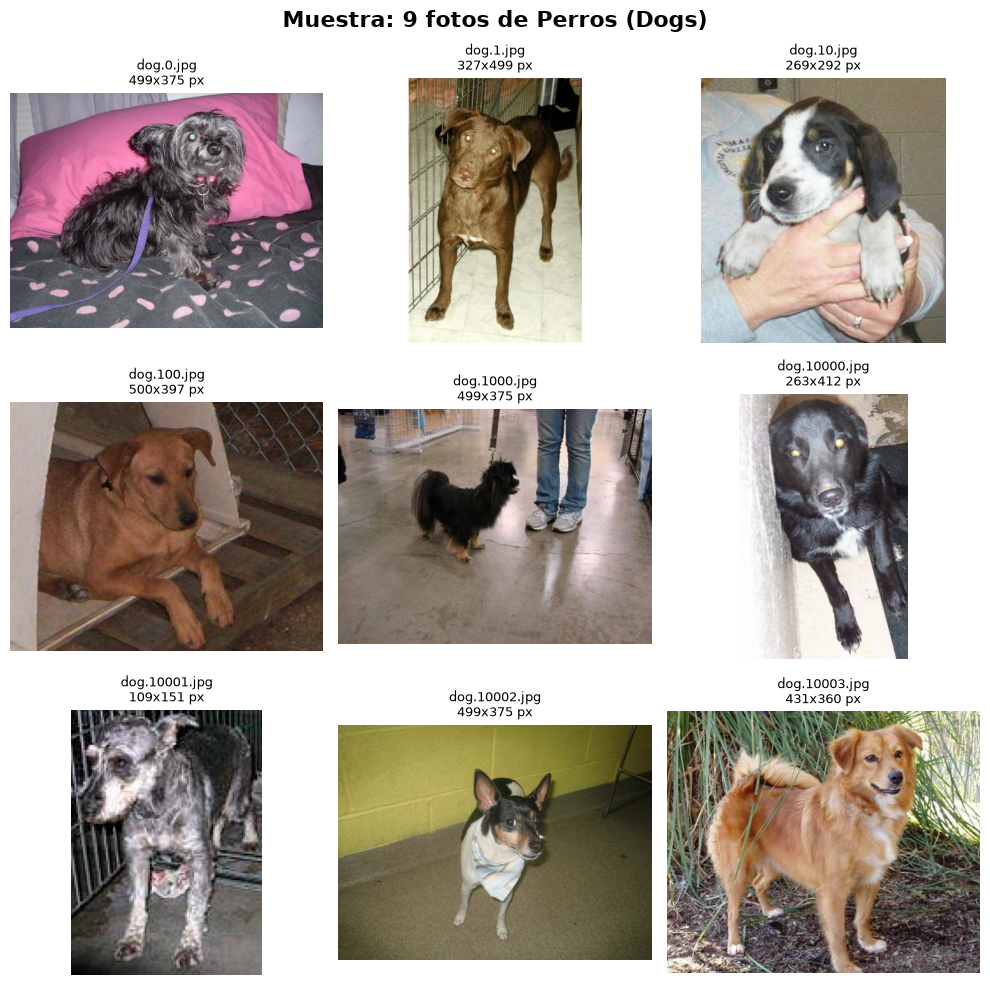

Visualizando gatos...


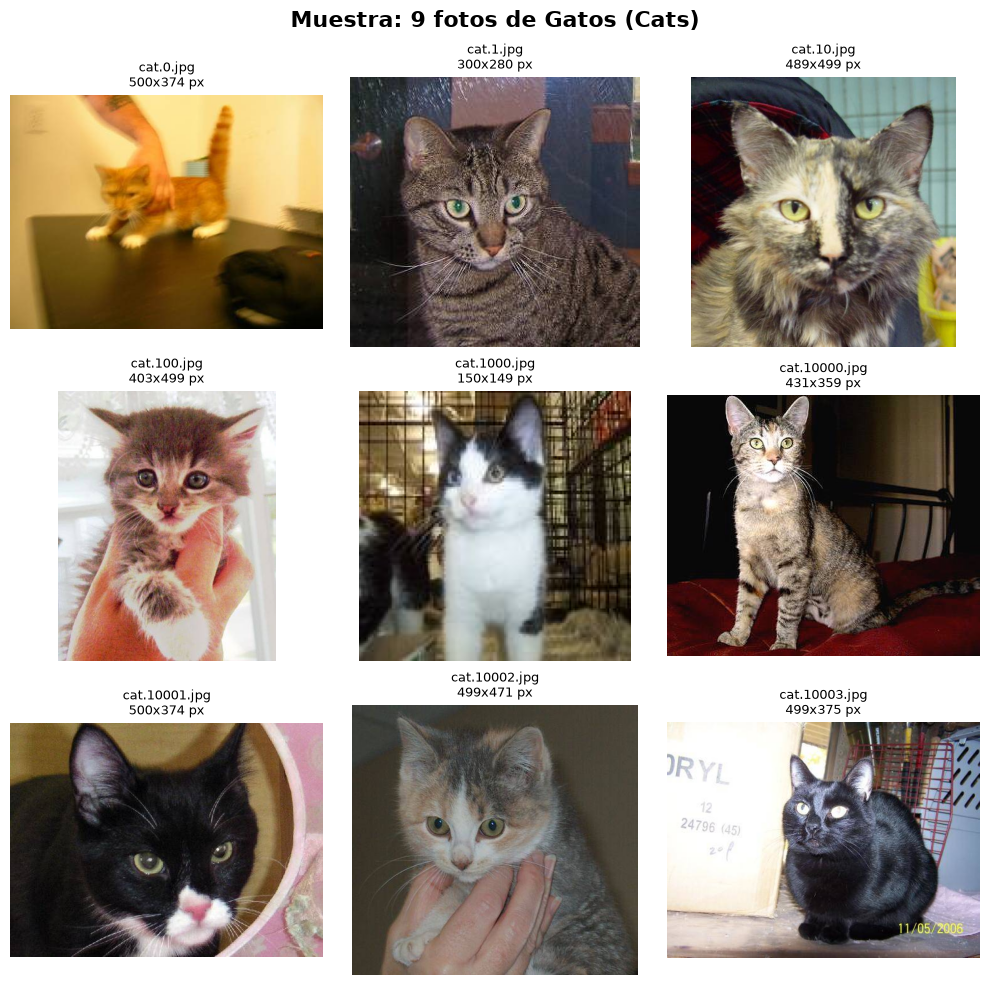

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
# Función para mostrar una cuadrícula de 3x3
def plot_sample_images(image_files, title, train_dir):
    fig, axes = plt.subplots(3, 3, figsize=(10, 10))
    fig.suptitle(title, fontsize=16, fontweight='bold')
    
    for i, ax in enumerate(axes.flat):
        img_path = train_dir / image_files[i]
        with Image.open(img_path) as img:
            ax.imshow(img)
            # Mostramos el nombre y las dimensiones originales de la foto
            ax.set_title(f"{image_files[i]}\n{img.size[0]}x{img.size[1]} px", fontsize=9)
            ax.axis('off')
            
    plt.tight_layout()
    plt.show()
# 1. Primeras 9 fotos de Perros
print("Visualizando perros...")
plot_sample_images(dog_files[:9], "Muestra: 9 fotos de Perros (Dogs)", train_dir)
# 2. Primeras 9 fotos de Gatos
print("Visualizando gatos...")
plot_sample_images(cat_files[:9], "Muestra: 9 fotos de Gatos (Cats)", train_dir)

In [ ]:
import shutil
import random

PROCESSED_DIR = Path("../data/processed")
TRAIN_PROCESSED = PROCESSED_DIR / "train"
TEST_PROCESSED = PROCESSED_DIR / "test"

# Subcarpetas por clase
for base in [TRAIN_PROCESSED, TEST_PROCESSED]:
    (base / "dogs").mkdir(parents=True, exist_ok=True)
    (base / "cats").mkdir(parents=True, exist_ok=True)

# Comprobar si ya se habían organizado antes para no repetir el proceso
if len(os.listdir(TRAIN_PROCESSED / "dogs")) == 0:
    print("Organizando imágenes en carpetas de train y test (80% / 20%)...")
    
    # Fijar semilla para reproducibilidad
    random.seed(42)
    
    # Perros
    random.shuffle(dog_files)
    split_dog = int(0.8 * len(dog_files))
    train_dogs, test_dogs = dog_files[:split_dog], dog_files[split_dog:]
    
    for f in train_dogs:
        shutil.copy(train_dir / f, TRAIN_PROCESSED / "dogs" / f)
    for f in test_dogs:
        shutil.copy(train_dir / f, TEST_PROCESSED / "dogs" / f)
        
    # Gatos
    random.shuffle(cat_files)
    split_cat = int(0.8 * len(cat_files))
    train_cats, test_cats = cat_files[:split_cat], cat_files[split_cat:]
    
    for f in train_cats:
        shutil.copy(train_dir / f, TRAIN_PROCESSED / "cats" / f)
    for f in test_cats:
        shutil.copy(train_dir / f, TEST_PROCESSED / "cats" / f)
        
    print("¡Organización completada con éxito!")
else:
    print("Las imágenes ya se encuentran organizadas en train y test.")

print(f"Train - Perros: {len(os.listdir(TRAIN_PROCESSED / 'dogs'))}, Gatos: {len(os.listdir(TRAIN_PROCESSED / 'cats'))}")
print(f"Test  - Perros: {len(os.listdir(TEST_PROCESSED / 'dogs'))}, Gatos: {len(os.listdir(TEST_PROCESSED / 'cats'))}")


Organizando imágenes en carpetas de train y test (80% / 20%)...
¡Organización completada con éxito!
Train - Perros: 10000, Gatos: 10000
Test  - Perros: 2500, Gatos: 2500


In [8]:
from pathlib import Path
from tensorflow.keras.preprocessing.image import ImageDataGenerator

PROCESSED_DIR = Path("../data/processed")
TRAIN_PROCESSED = PROCESSED_DIR / "train"
TEST_PROCESSED = PROCESSED_DIR / "test"

# EfficientNet espera valores de 0 a 255 (no aplicamos rescale)
train_datagen = ImageDataGenerator()
test_datagen = ImageDataGenerator()

trdata = train_datagen.flow_from_directory(
    directory=str(TRAIN_PROCESSED),
    target_size=(200, 200),
    batch_size=32,
    class_mode="categorical",
    shuffle=True,
    seed=42
)

tsdata = test_datagen.flow_from_directory(
    directory=str(TEST_PROCESSED),
    target_size=(200, 200),
    batch_size=32,
    class_mode="categorical",
    shuffle=False
)




Found 20000 images belonging to 2 classes.
Found 5000 images belonging to 2 classes.


In [9]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.optimizers import Adam

# 1. Base convolucional EfficientNet-B0
# Usamos weights='imagenet' para transfer learning. 
# Al congelar la base (trainable = False), entrenar en CPU toma pocos minutos por época en vez de horas.
base_model = EfficientNetB0(
    include_top=False,
    weights='imagenet',
    input_shape=(200, 200, 3)
)
base_model.trainable = False  # Congelamos las capas base para entrenar solo la cabeza clasificadora

# 2. Ensamblar la arquitectura secuencial
model = Sequential()
model.add(base_model)
model.add(GlobalAveragePooling2D())
model.add(Dense(units=128, activation="relu"))
model.add(Dropout(0.3))  # Previene sobreajuste
model.add(Dense(units=2, activation="softmax"))

# 3. Compilación del modelo
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# 4. Ver estructura de parámetros
model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,797 (16.07 MB)

 Trainable params: 164,226 (641.51 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [13]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from pathlib import Path

# 1. Asegurar la carpeta models/
MODELS_DIR = Path("../models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = MODELS_DIR / "best_model.keras"

# 2. Configurar Callbacks
callbacks = [
    ModelCheckpoint(
        filepath=str(CHECKPOINT_PATH),
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    )
]

# 3. Entrenar el modelo
# 5 épocas son ideales para transfer learning sobre la base congelada
EPOCHS = 3

print(f"Iniciando entrenamiento por {EPOCHS} épocas...")
history = model.fit(
    trdata,
    steps_per_epoch=150,
    validation_data=tsdata,
    validation_steps=50,
    epochs=EPOCHS,
    callbacks=callbacks
)


Iniciando entrenamiento por 3 épocas...
Epoch 1/3
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step - accuracy: 0.9902 - loss: 0.0298
Epoch 1: val_accuracy improved from None to 0.99500, saving model to ..\models\best_model.keras

Epoch 1: finished saving model to ..\models\best_model.keras
150/150 ━━━━━━━━━━━━━━━━━━━━ 45s 300ms/step - accuracy: 0.9902 - loss: 0.0298 - val_accuracy: 0.9950 - val_loss: 0.0209
Epoch 2/3
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 223ms/step - accuracy: 0.9885 - loss: 0.0313
Epoch 2: val_accuracy did not improve from 0.99500
150/150 ━━━━━━━━━━━━━━━━━━━━ 44s 297ms/step - accuracy: 0.9885 - loss: 0.0313 - val_accuracy: 0.9931 - val_loss: 0.0243
Epoch 3/3
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 228ms/step - accuracy: 0.9906 - loss: 0.0313
Epoch 3: val_accuracy did not improve from 0.99500
150/150 ━━━━━━━━━━━━━━━━━━━━ 46s 309ms/step - accuracy: 0.9906 - loss: 0.0313 - val_accuracy: 0.9950 - val_loss: 0.0209
Restoring model weights from the end of the best epoch: 1.


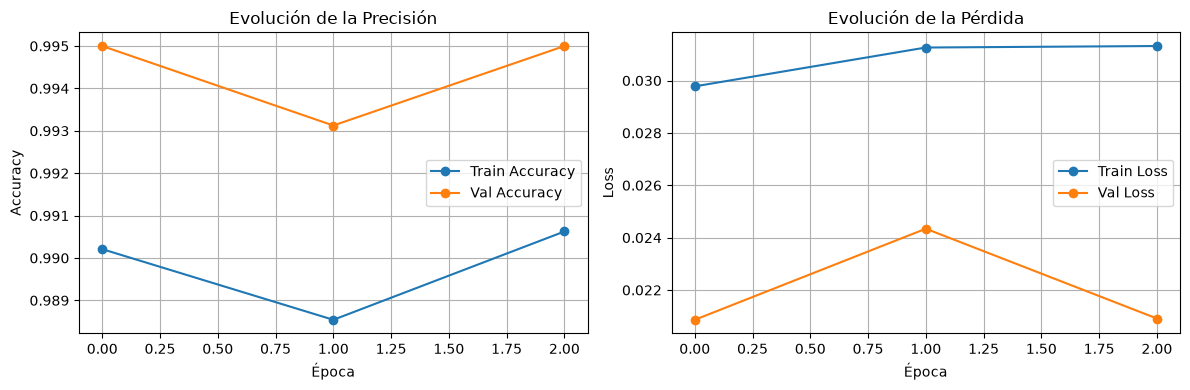

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Gráfico de Precisión (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Val Accuracy', marker='o')
plt.title('Evolución de la Precisión')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Gráfico de Pérdida (Loss)
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', marker='o')
plt.plot(history.history['val_loss'], label='Val Loss', marker='o')
plt.title('Evolución de la Pérdida')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


Cargando el mejor modelo...
✅ ¡Modelo cargado exitosamente desde models/best_model.keras!

157/157 ━━━━━━━━━━━━━━━━━━━━ 37s 219ms/step - accuracy: 0.9920 - loss: 0.0277
🎯 Test Loss:     0.0277
🎯 Test Accuracy: 99.20%

157/157 ━━━━━━━━━━━━━━━━━━━━ 37s 229ms/step
📊 Reporte de Clasificación:
              precision    recall  f1-score   support

        cats       0.99      1.00      0.99      2500
        dogs       1.00      0.99      0.99      2500

    accuracy                           0.99      5000
   macro avg       0.99      0.99      0.99      5000
weighted avg       0.99      0.99      0.99      5000



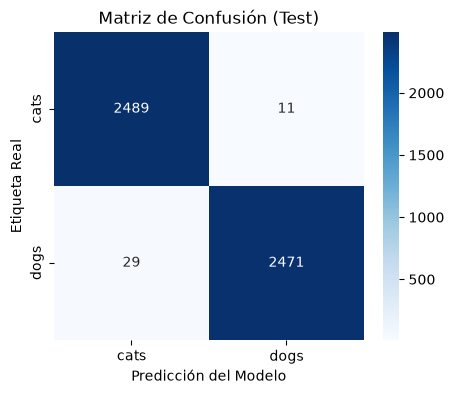

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


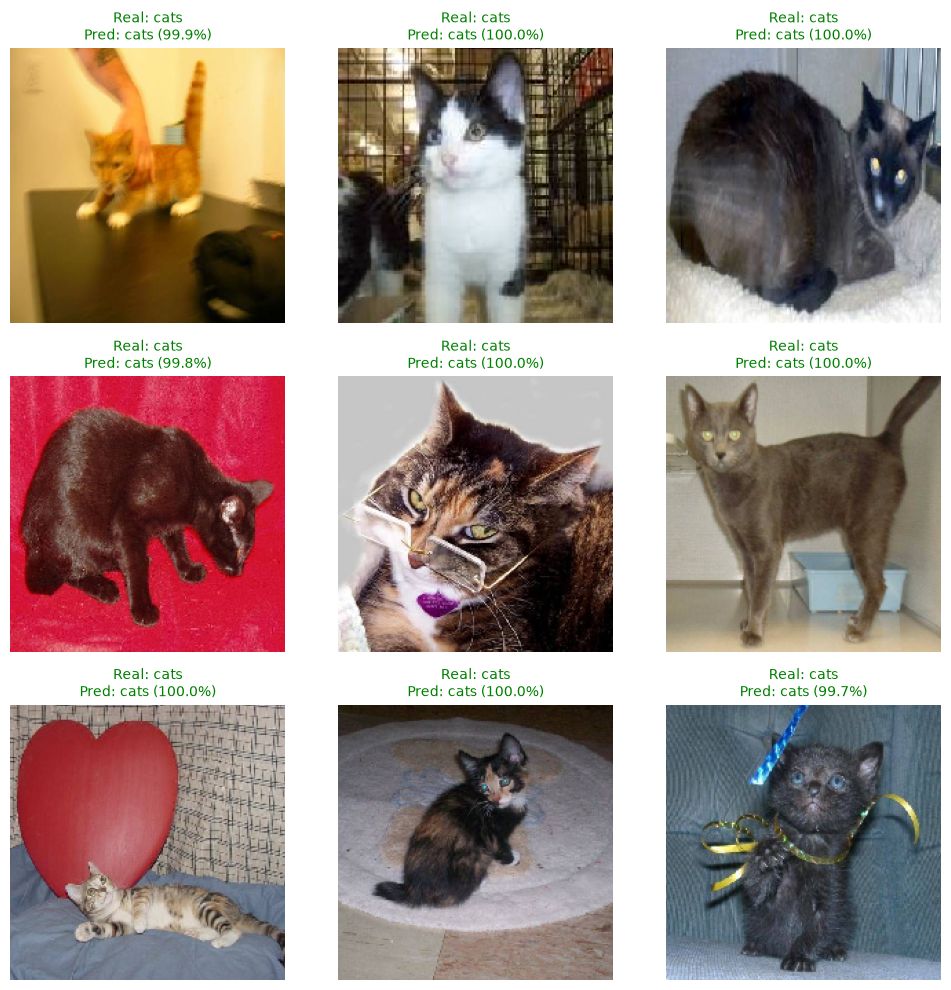

In [15]:
from tensorflow.keras.models import load_model
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# 1. Cargar el mejor modelo guardado por el Checkpoint
print("Cargando el mejor modelo...")
best_model = load_model("../models/best_model.keras")
print("✅ ¡Modelo cargado exitosamente desde models/best_model.keras!\n")

# 2. Evaluación cuantitativa sobre el conjunto de test completo
eval_results = best_model.evaluate(tsdata)
print(f"🎯 Test Loss:     {eval_results[0]:.4f}")
print(f"🎯 Test Accuracy: {eval_results[1]*100:.2f}%\n")

# 3. Predicciones completas y Matriz de Confusión
tsdata.reset()
class_names = list(tsdata.class_indices.keys())  # ['cats', 'dogs']

y_pred_probs = best_model.predict(tsdata)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = tsdata.classes

print("📊 Reporte de Clasificación:")
print(classification_report(y_true, y_pred, target_names=class_names))

# Gráfico de Matriz de Confusión
plt.figure(figsize=(5, 4))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("Matriz de Confusión (Test)")
plt.xlabel("Predicción del Modelo")
plt.ylabel("Etiqueta Real")
plt.show()

# 4. Galería visual: 9 fotos de prueba con etiqueta real vs predicción
plt.figure(figsize=(10, 10))
sample_images, sample_labels = next(tsdata)
sample_preds = best_model.predict(sample_images)

for i in range(9):
    plt.subplot(3, 3, i + 1)
    # Mostramos la imagen en formato uint8
    plt.imshow(sample_images[i].astype("uint8"))
    
    real_label = class_names[np.argmax(sample_labels[i])]
    pred_label = class_names[np.argmax(sample_preds[i])]
    confidence = np.max(sample_preds[i]) * 100
    
    color = "green" if real_label == pred_label else "red"
    plt.title(f"Real: {real_label}\nPred: {pred_label} ({confidence:.1f}%)", color=color, fontsize=10)
    plt.axis("off")

plt.tight_layout()
plt.show()
